Linear regression is the one model whose optimum can be written down in closed form and
verified by hand. Everything harder &mdash; logistic regression, SVMs, neural networks &mdash;
replaces one piece of it and loses that closed form, so it is worth seeing exactly where
the solution comes from.

The model is a weighted sum:

$$\hat{y}_i = w_0 + w_1 x_{i1} + \dots + w_p x_{ip} = \mathbf{x}_i^\top \mathbf{w}$$

and the loss is squared error:

$$\mathcal{L}(\mathbf{w}) = \sum_{i=1}^{n}(y_i - \mathbf{x}_i^\top\mathbf{w})^2
= \lVert \mathbf{y} - X\mathbf{w} \rVert^2$$

Below: the design matrix, $X^\top X$ and its inverse printed entry by entry, the normal
equation solved by hand, the same answer reached again by gradient descent, then $R^2$,
the residuals, and what ridge and lasso change. Every result is checked against
scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

12 EEG recordings. The target is `y_reg` &mdash; seizure burden in minutes per hour &mdash; and
the three features are the same ones used in the tree walkthroughs.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

---
# 2. The Design Matrix

The intercept $w_0$ is handled by adding a column of ones. After that the intercept is
just another weight and the whole model is a single matrix product:

$$\hat{\mathbf{y}} = X\mathbf{w}, \qquad X \in \mathbb{R}^{12 \times 4},\;\; \mathbf{w} \in \mathbb{R}^{4}$$

In [3]:
y = y_reg.astype(float)
Xd = np.column_stack([np.ones(n_samples), X])       # prepend the bias column
col_names = ["1 (bias)"] + feature_names

print(f"design matrix X: {Xd.shape}   ({n_samples} rows, 1 bias + {n_features} features)\n")
hdr = f"{'id':>6}  " + "  ".join(f"{c:>12}" for c in col_names) + f"  |{'y':>8}"
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  " + "  ".join(f"{v:>12.2f}" for v in Xd[i]) +
          f"  |{y[i]:>8.2f}")
print("-" * len(hdr))
print(f"\nthe model has {Xd.shape[1]} unknowns and {n_samples} equations - overdetermined,")
print("so in general no w makes every residual zero. Least squares finds the w that")
print("makes them as small as possible in the squared sense.")

design matrix X: (12, 4)   (12 rows, 1 bias + 3 features)

    id      1 (bias)   line_length    spike_rate           age  |       y
-------------------------------------------------------------------------
 rec00          1.00         12.00          0.50         24.00  |    0.20
 rec01          1.00         15.00          1.20         31.00  |    0.50
 rec02          1.00         42.00          6.80         58.00  |    6.40
 rec03          1.00         38.00          5.10         47.00  |    4.80
 rec04          1.00         11.00          0.30         19.00  |    0.10
 rec05          1.00         55.00          8.20         63.00  |    9.10
 rec06          1.00         40.00          1.90         35.00  |    3.50
 rec07          1.00         47.00          7.40         52.00  |    7.20
 rec08          1.00         14.00          0.80         28.00  |    0.30
 rec09          1.00         51.00          6.10         60.00  |    6.90
 rec10          1.00         45.00          2.40     

---
# 3. The Normal Equation

Write the loss in matrix form and differentiate:

$$\mathcal{L}(\mathbf{w}) = (\mathbf{y} - X\mathbf{w})^\top(\mathbf{y} - X\mathbf{w})
= \mathbf{y}^\top\mathbf{y} - 2\mathbf{w}^\top X^\top \mathbf{y} + \mathbf{w}^\top X^\top X \mathbf{w}$$

$$\frac{\partial \mathcal{L}}{\partial \mathbf{w}} = -2X^\top\mathbf{y} + 2X^\top X\mathbf{w} = 0$$

$$\boxed{\;\mathbf{w}^{*} = (X^\top X)^{-1} X^\top \mathbf{y}\;}$$

The loss is a **convex quadratic**, so this stationary point is the global minimum &mdash;
there are no local minima to worry about and no learning rate to tune.

The geometry is worth holding onto: $X\mathbf{w}$ can only ever land in the column space
of $X$. Least squares picks the point in that subspace closest to $\mathbf{y}$, which
makes the residual **orthogonal to every column of $X$**. That orthogonality is checked
numerically below.

In [4]:
XtX = Xd.T @ Xd
Xty = Xd.T @ y

print("STEP 1 : X^T X")
print("=" * 78)
show_matmul(Xd.T, Xd, XtX, "X^T", "X", "X^T X", i=0, j=0,
            note="(4,12) @ (12,4) -> (4,4): a small square matrix, whatever n is")

print("\n\nSTEP 2 : X^T y")
print("=" * 78)
show_matrix(Xty[None, :], "X^T y", cols=col_names)
print(f"\n   element 0 = sum of y            = {y.sum():.4f}")
print(f"   element 1 = sum of x1 * y        = {(X[:,0]*y).sum():.4f}")
print(f"   check against the array          : "
      f"{np.isclose(Xty[1], (X[:,0]*y).sum())}")

STEP 1 : X^T X
  X^T (4, 12)   @   X (12, 4)   =   X^T X (4, 4)
  shape rule: (4 x 12) @ (12 x 4) -> (4 x 4)   inner dim 12 cancels
  (4,12) @ (12,4) -> (4,4): a small square matrix, whatever n is

X^T (4, 12) =
            0 |   +1.000    +1.000    +1.000    +1.000    +1.000    +1.000    +1.000    +1.000    +1.000    +1.000    +1.000    +1.000
            1 |  +12.000   +15.000   +42.000   +38.000   +11.000   +55.000   +40.000   +47.000   +14.000   +51.000   +45.000   +35.000
            2 |   +0.500    +1.200    +6.800    +5.100    +0.300    +8.200    +1.900    +7.400    +0.800    +6.100    +2.400    +4.700
            3 |  +24.000   +31.000   +58.000   +47.000   +19.000   +63.000   +35.000   +52.000   +28.000   +60.000   +41.000   +30.000

X (12, 4) =
            0 |   +1.000   +12.000    +0.500   +24.000
            1 |   +1.000   +15.000    +1.200   +31.000
            2 |   +1.000   +42.000    +6.800   +58.000
            3 |   +1.000   +38.000    +5.100   +47.000
            4 |

In [5]:
print("STEP 3 : invert X^T X")
print("=" * 78)
XtX_inv = np.linalg.inv(XtX)
show_matrix(XtX_inv, "(X^T X)^-1", cols=col_names, fmt="{:+11.6f}")

ident = XtX @ XtX_inv
print()
show_matrix(ident, "X^T X  @  (X^T X)^-1   (should be the identity)",
            fmt="{:+9.5f}")
print(f"\nis it the identity? {np.allclose(ident, np.eye(4))}")
print(f"condition number of X^T X = {np.linalg.cond(XtX):,.1f}")
print("\nA large condition number means the inverse amplifies small changes in the")
print("data into large changes in w - that is multicollinearity, and it is exactly")
print("what ridge regression is built to control.")

STEP 3 : invert X^T X
(X^T X)^-1 (4, 4) =
               1 (bias)line_lengthspike_rate       age
            0 |   +1.447993    -0.000838    +0.208314    -0.052242
            1 |   -0.000838    +0.001639    -0.002661    -0.001092
            2 |   +0.208314    -0.002661    +0.065530    -0.009011
            3 |   -0.052242    -0.001092    -0.009011    +0.003029

X^T X  @  (X^T X)^-1   (should be the identity) (4, 4) =
            0 |  +1.00000   +0.00000   +0.00000   -0.00000
            1 |  +0.00000   +1.00000   +0.00000   -0.00000
            2 |  -0.00000   +0.00000   +1.00000   -0.00000
            3 |  +0.00000   -0.00000   -0.00000   +1.00000

is it the identity? True
condition number of X^T X = 57,391.9

A large condition number means the inverse amplifies small changes in the
data into large changes in w - that is multicollinearity, and it is exactly
what ridge regression is built to control.


In [6]:
print("STEP 4 : w* = (X^T X)^-1 X^T y")
print("=" * 78)
w = XtX_inv @ Xty
show_matmul(XtX_inv, Xty[:, None], w[:, None], "(X^T X)^-1", "X^T y", "w*", i=0, j=0)

print("\n\nfitted coefficients\n")
print(f"{'term':>14}  {'weight':>12}")
print("-" * 30)
for c, v in zip(col_names, w):
    print(f"{c:>14}  {v:>12.6f}")
print("-" * 30)

print(f"\nthe fitted model:")
terms = " + ".join(f"{w[k+1]:+.4f}*{feature_names[k]}" for k in range(n_features))
print(f"   y_hat = {w[0]:+.4f} {terms}")
print(f"\nReading a coefficient: holding the other features fixed, one extra unit of")
print(f"{feature_names[1]} is associated with {w[2]:+.4f} more minutes of seizure burden.")
print(f"'Associated with', not 'causes' - this is a correlational fit.")

STEP 4 : w* = (X^T X)^-1 X^T y
  (X^T X)^-1 (4, 4)   @   X^T y (4, 1)   =   w* (4, 1)
  shape rule: (4 x 4) @ (4 x 1) -> (4 x 1)   inner dim 4 cancels

(X^T X)^-1 (4, 4) =
            0 |   +1.448    -0.001    +0.208    -0.052
            1 |   -0.001    +0.002    -0.003    -0.001
            2 |   +0.208    -0.003    +0.066    -0.009
            3 |   -0.052    -0.001    -0.009    +0.003

X^T y (4, 1) =
            0 |  +44.700
            1 | +2012.700
            2 | +268.720
            3 | +2300.200

w* (4, 1) =
            0 |   -1.150
            1 |   +0.034
            2 |   +0.839
            3 |   +0.013

  worked element  w*[0,0]  =  row 0 of (X^T X)^-1  .  column 0 of X^T y
      row 0 of (X^T X)^-1 = [ 1.448  -0.0008  0.2083 -0.0522]
      col 0 of X^T y = [  44.7  2012.7   268.72 2300.2 ]
      (+1.4480)*(+44.7000) + (-0.0008)*(+2012.7000) + (+0.2083)*(+268.7200) + (-0.0522)*(+2300.2000)
      = -1.149744   |  from array: -1.149744   |  MATCH: True


fitted coefficients


### The residuals are orthogonal to the features

If the fit is truly optimal, no column of $X$ can explain any of what is left over:

$$X^\top(\mathbf{y} - X\mathbf{w}^{*}) = \mathbf{0}$$

Any non-zero entry here would mean some feature still carries unused signal &mdash; and the
loss could be reduced further, contradicting optimality.

In [7]:
y_hat = Xd @ w
resid = y - y_hat

print(f"{'id':>6}  {'y':>8}  {'y_hat':>9}  {'residual':>10}")
print("-" * 38)
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {y[i]:>8.2f}  {y_hat[i]:>9.4f}  {resid[i]:>10.4f}")
print("-" * 38)
print(f"{'SUM':>6}  {y.sum():>8.2f}  {y_hat.sum():>9.4f}  {resid.sum():>10.6f}")

orth = Xd.T @ resid
print(f"\nX^T (y - Xw) = {np.round(orth, 9)}")
print(f"all zero (to numerical precision)? {np.allclose(orth, 0, atol=1e-9)}")
print(f"\n   the first entry is the sum of residuals - it is zero because of the")
print(f"   bias column, which is why a model WITH an intercept always has")
print(f"   residuals summing to zero: {resid.sum():.2e}")

    id         y      y_hat    residual
--------------------------------------
 rec00      0.20     0.0013      0.1987
 rec01      0.50     0.7849     -0.2849
 rec02      6.40     6.7705     -0.3705
 rec03      4.80     5.0601     -0.2601
 rec04      0.10    -0.2674      0.3674
 rec05      9.10     8.4580      0.6420
 rec06      3.50     2.2836      1.2164
 rec07      7.20     7.3657     -0.1657
 rec08      0.30     0.3750     -0.0750
 rec09      6.90     6.5186      0.3814
 rec10      1.60     2.9547     -1.3547
 rec11      4.10     4.3951     -0.2951
--------------------------------------
   SUM     44.70    44.7000    0.000000

X^T (y - Xw) = [0. 0. 0. 0.]
all zero (to numerical precision)? True

   the first entry is the sum of residuals - it is zero because of the
   bias column, which is why a model WITH an intercept always has
   residuals summing to zero: 8.76e-13


---
# 4. How Good Is the Fit?

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}
= 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}}$$

$R^2$ compares the model against the simplest possible baseline: always predicting the
mean. $R^2 = 0$ means the model is no better than that; $R^2 = 1$ means it fits perfectly.

**A warning that matters here:** $R^2$ never decreases when you add a feature, even a
random one, because the extra column can only ever be *used* or *ignored*. Adjusted $R^2$
penalises that.

In [8]:
ss_res = (resid ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot
n, p = n_samples, n_features
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"SS_res = sum of squared residuals   = {ss_res:.6f}")
print(f"SS_tot = sum of squared deviations  = {ss_tot:.6f}")
print(f"         (from the mean y = {y.mean():.4f})\n")
print(f"R^2      = 1 - {ss_res:.4f} / {ss_tot:.4f} = {r2:.6f}")
print(f"adj. R^2 = 1 - (1 - {r2:.4f}) * ({n}-1)/({n}-{p}-1) = {adj_r2:.6f}")
print(f"\nRMSE = sqrt({ss_res:.4f} / {n}) = {np.sqrt(ss_res/n):.6f} minutes/hour")
print(f"MAE  = {np.abs(resid).mean():.6f}")
print(f"\nfor scale: std(y) = {y.std():.4f}, so the model's typical error is")
print(f"{np.sqrt(ss_res/n)/y.std():.1%} of the natural spread in the target.")

print("\n\nadding a column of PURE NOISE, to show R^2 cannot fall:\n")
rng_n = np.random.default_rng(0)
for extra in (1, 3, 6):
    Xn = np.column_stack([Xd, rng_n.normal(size=(n_samples, extra))])
    wn = np.linalg.lstsq(Xn, y, rcond=None)[0]
    r2n = 1 - ((y - Xn @ wn) ** 2).sum() / ss_tot
    adjn = 1 - (1 - r2n) * (n - 1) / (n - (p + extra) - 1)
    print(f"   +{extra} random column(s): R^2 = {r2n:.6f}   adj R^2 = {adjn:>9.6f}")
print(f"\n   R^2 climbs toward 1 with meaningless columns; adjusted R^2 turns back.")

SS_res = sum of squared residuals   = 4.453102
SS_tot = sum of squared deviations  = 111.762500
         (from the mean y = 3.7250)

R^2      = 1 - 4.4531 / 111.7625 = 0.960156
adj. R^2 = 1 - (1 - 0.9602) * (12-1)/(12-3-1) = 0.945214

RMSE = sqrt(4.4531 / 12) = 0.609173 minutes/hour
MAE  = 0.467647

for scale: std(y) = 3.0518, so the model's typical error is
20.0% of the natural spread in the target.


adding a column of PURE NOISE, to show R^2 cannot fall:

   +1 random column(s): R^2 = 0.965113   adj R^2 =  0.945177
   +3 random column(s): R^2 = 0.982147   adj R^2 =  0.960723
   +6 random column(s): R^2 = 0.988970   adj R^2 =  0.939337

   R^2 climbs toward 1 with meaningless columns; adjusted R^2 turns back.


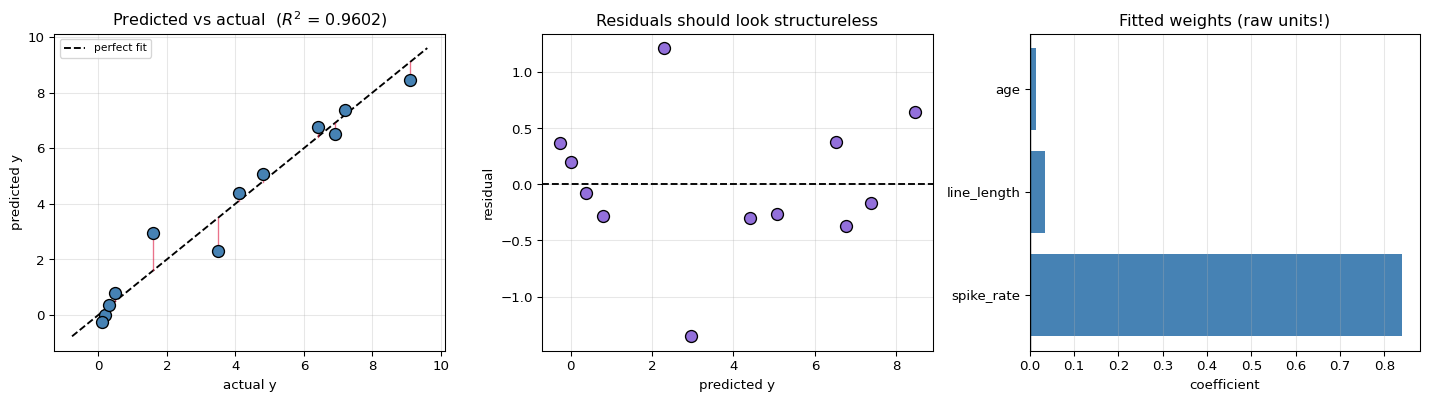

Middle panel: any visible pattern (a curve, a funnel) would mean the linear
form is wrong or the variance is not constant. With 12 points there is not
enough data to judge that seriously.

Right panel: these coefficients are in RAW units, so their sizes are not
comparable - age runs to 60 while spike_rate runs to 8. Comparing importance
requires standardising the features first.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

axes[0].scatter(y, y_hat, s=80, color="steelblue", edgecolor="k", zorder=3)
lo, hi = min(y.min(), y_hat.min()) - .5, max(y.max(), y_hat.max()) + .5
axes[0].plot([lo, hi], [lo, hi], "k--", lw=1.4, label="perfect fit")
for i in range(n_samples):
    axes[0].plot([y[i], y[i]], [y[i], y_hat[i]], color="crimson", lw=1, alpha=.6)
axes[0].set(xlabel="actual y", ylabel="predicted y",
            title=f"Predicted vs actual  ($R^2$ = {r2:.4f})")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

axes[1].scatter(y_hat, resid, s=80, color="mediumpurple", edgecolor="k", zorder=3)
axes[1].axhline(0, color="k", ls="--", lw=1.4)
axes[1].set(xlabel="predicted y", ylabel="residual",
            title="Residuals should look structureless")
axes[1].grid(alpha=.3)

order = np.argsort(np.abs(w[1:]))[::-1]
axes[2].barh([feature_names[k] for k in order], [w[k+1] for k in order],
             color=["crimson" if w[k+1] < 0 else "steelblue" for k in order])
axes[2].axvline(0, color="k", lw=1)
axes[2].set(xlabel="coefficient", title="Fitted weights (raw units!)")
axes[2].grid(alpha=.3, axis="x")

plt.tight_layout(); plt.show()

print("Middle panel: any visible pattern (a curve, a funnel) would mean the linear")
print("form is wrong or the variance is not constant. With 12 points there is not")
print("enough data to judge that seriously.")
print()
print("Right panel: these coefficients are in RAW units, so their sizes are not")
print("comparable - age runs to 60 while spike_rate runs to 8. Comparing importance")
print("requires standardising the features first.")

---
# 5. How Learning Actually Happens

The closed form gave the answer in one step, which is convenient but hides the process.
Every other model in this series &mdash; logistic regression, SVMs, neural networks &mdash; has to
*learn* its weights by repeating one loop:

> **predict &rarr; measure the error &rarr; find which direction reduces it &rarr; take a small step &rarr; repeat**

This section runs that loop with every number written out, so the mechanism is visible
rather than asserted. To keep the arithmetic small enough to follow, it uses **one
feature plus a bias** &mdash; two parameters, which also means the loss surface can be drawn.

### The three pieces

**1. The loss** &mdash; how wrong we are right now (mean squared error):

$$\mathcal{L}(w_0, w_1) = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - (w_0 + w_1 x_i)\big)^2$$

**2. The derivatives** &mdash; how the loss changes if each weight nudges up. Using the chain
rule on $(y_i - w_0 - w_1x_i)^2$:

$$\frac{\partial\mathcal{L}}{\partial w_0} = \frac{2}{n}\sum_i \big(\hat{y}_i - y_i\big)
\qquad\qquad
\frac{\partial\mathcal{L}}{\partial w_1} = \frac{2}{n}\sum_i \big(\hat{y}_i - y_i\big)\,x_i$$

Read them directly: $\partial\mathcal{L}/\partial w_0$ is (twice) the **average error** &mdash;
if predictions are too low overall, raise the intercept. $\partial\mathcal{L}/\partial w_1$
is (twice) the average error **weighted by $x$** &mdash; if the errors are worse where $x$ is
large, change the slope.

**3. The update** &mdash; step *against* the gradient, because the gradient points uphill:

$$w \leftarrow w - \eta\,\frac{\partial\mathcal{L}}{\partial w}$$

In [10]:
xs_gd = X[:, 1]                 # spike_rate, raw units
ETA = 0.02
w_gd = np.array([0.0, 0.0])     # start from nothing: predict 0 for everything

def predict(w_, xv):
    return w_[0] + w_[1]*xv

def mse(w_, xv=xs_gd, yv=y):
    return float(np.mean((yv - predict(w_, xv))**2))

def grads(w_, xv=xs_gd, yv=y):
    e = predict(w_, xv) - yv            # error = prediction - truth
    return np.array([2*e.mean(), 2*np.mean(e*xv)]), e

print(f"model      : y_hat = w0 + w1 * {feature_names[1]}")
print(f"start at   : w0 = {w_gd[0]}, w1 = {w_gd[1]}   (predicting 0 for every recording)")
print(f"learning rate eta = {ETA}")
print(f"loss at the start = {mse(w_gd):.6f}\n")
print(f"for reference, the closed-form optimum for this 1-feature model is:")
A1 = np.column_stack([np.ones(n_samples), xs_gd])
w_star = np.linalg.lstsq(A1, y, rcond=None)[0]
print(f"   w0* = {w_star[0]:+.6f}, w1* = {w_star[1]:+.6f}, loss* = {mse(w_star):.6f}")

model      : y_hat = w0 + w1 * spike_rate
start at   : w0 = 0.0, w1 = 0.0   (predicting 0 for every recording)
learning rate eta = 0.02
loss at the start = 23.189167

for reference, the closed-form optimum for this 1-feature model is:
   w0* = -0.302061, w1* = +1.064421, loss* = 0.478401


### Four epochs, every number

Each block below is one full pass: the current weights, what they predict for all 12
recordings, the error on each, the loss, both derivatives summed term by term, and the
resulting update.

In [11]:
w_gd = np.array([0.0, 0.0])
path = [w_gd.copy()]
losses = [mse(w_gd)]

for epoch in range(1, 5):
    L = mse(w_gd)
    g, e = grads(w_gd)
    yh_e = predict(w_gd, xs_gd)

    print("=" * 78)
    print(f"  EPOCH {epoch}      w0 = {w_gd[0]:+.6f}      w1 = {w_gd[1]:+.6f}")
    print("=" * 78)

    print(f"\nSTEP 1 - predict, and measure the error\n")
    print(f"{'id':>6}  {'x':>7}  {'y':>7}  {'y_hat = w0 + w1*x':>19}  "
          f"{'error (y_hat - y)':>18}  {'error^2':>9}")
    print("-" * 74)
    for i in range(n_samples):
        print(f"{rec_ids[i]:>6}  {xs_gd[i]:>7.1f}  {y[i]:>7.2f}  "
              f"{w_gd[0]:+.4f} + {w_gd[1]:+.4f}*{xs_gd[i]:.1f} = {yh_e[i]:>7.4f}  "
              f"{e[i]:>18.4f}  {e[i]**2:>9.4f}")
    print("-" * 74)
    print(f"   loss = mean of the last column = {np.sum(e**2):.4f} / {n_samples} "
          f"= {L:.6f}")

    print(f"\nSTEP 2 - the two derivatives\n")
    print(f"   dL/dw0 = (2/n) * sum(error)")
    print(f"          = (2/{n_samples}) * ({' + '.join(f'{v:+.3f}' for v in e[:6])} + ...)")
    print(f"          = (2/{n_samples}) * {e.sum():+.6f}")
    print(f"          = {g[0]:+.6f}")
    print()
    print(f"   dL/dw1 = (2/n) * sum(error * x)")
    prods = e * xs_gd
    print(f"          = (2/{n_samples}) * ({' + '.join(f'{v:+.2f}' for v in prods[:6])} + ...)")
    print(f"          = (2/{n_samples}) * {prods.sum():+.6f}")
    print(f"          = {g[1]:+.6f}")
    print(f"\n   both negative -> the loss falls if we INCREASE both weights"
          if (g < 0).all() else "")

    print(f"\nSTEP 3 - step against the gradient\n")
    new_w = w_gd - ETA * g
    print(f"   w0 <- {w_gd[0]:+.6f} - {ETA} * ({g[0]:+.6f}) = "
          f"{w_gd[0]:+.6f} {-ETA*g[0]:+.6f} = {new_w[0]:+.6f}")
    print(f"   w1 <- {w_gd[1]:+.6f} - {ETA} * ({g[1]:+.6f}) = "
          f"{w_gd[1]:+.6f} {-ETA*g[1]:+.6f} = {new_w[1]:+.6f}")

    w_gd = new_w
    path.append(w_gd.copy())
    losses.append(mse(w_gd))
    print(f"\n   loss: {L:.6f}  ->  {losses[-1]:.6f}   "
          f"({'DOWN' if losses[-1] < L else 'UP'} by {abs(losses[-1]-L):.6f})")
    print()

  EPOCH 1      w0 = +0.000000      w1 = +0.000000

STEP 1 - predict, and measure the error

    id        x        y    y_hat = w0 + w1*x   error (y_hat - y)    error^2
--------------------------------------------------------------------------
 rec00      0.5     0.20  +0.0000 + +0.0000*0.5 =  0.0000             -0.2000     0.0400
 rec01      1.2     0.50  +0.0000 + +0.0000*1.2 =  0.0000             -0.5000     0.2500
 rec02      6.8     6.40  +0.0000 + +0.0000*6.8 =  0.0000             -6.4000    40.9600
 rec03      5.1     4.80  +0.0000 + +0.0000*5.1 =  0.0000             -4.8000    23.0400
 rec04      0.3     0.10  +0.0000 + +0.0000*0.3 =  0.0000             -0.1000     0.0100
 rec05      8.2     9.10  +0.0000 + +0.0000*8.2 =  0.0000             -9.1000    82.8100
 rec06      1.9     3.50  +0.0000 + +0.0000*1.9 =  0.0000             -3.5000    12.2500
 rec07      7.4     7.20  +0.0000 + +0.0000*7.4 =  0.0000             -7.2000    51.8400
 rec08      0.8     0.30  +0.0000 + +0.0000*

### The same loop, continued to convergence

The gradient shrinks as the weights approach the optimum &mdash; at the minimum it is exactly
zero, which is the same condition the normal equation solved directly in section 3.

In [12]:
w_run = np.array([0.0, 0.0])
full_path, full_loss = [w_run.copy()], [mse(w_run)]
for _ in range(3000):
    g, _ = grads(w_run)
    w_run = w_run - ETA * g
    full_path.append(w_run.copy())
    full_loss.append(mse(w_run))
full_path = np.array(full_path)

print(f"{'epoch':>7}  {'w0':>11}  {'w1':>11}  {'loss':>12}  "
      f"{'dL/dw0':>11}  {'dL/dw1':>11}  {'|gradient|':>11}")
print("-" * 82)
for ep in [0, 1, 2, 3, 4, 5, 10, 25, 50, 100, 250, 500, 1000, 2000, 3000]:
    ww = full_path[ep]
    gg, _ = grads(ww)
    print(f"{ep:>7}  {ww[0]:>11.6f}  {ww[1]:>11.6f}  {full_loss[ep]:>12.6f}  "
          f"{gg[0]:>11.6f}  {gg[1]:>11.6f}  {np.linalg.norm(gg):>11.3e}")
print("-" * 82)
print(f"{'exact':>7}  {w_star[0]:>11.6f}  {w_star[1]:>11.6f}  {mse(w_star):>12.6f}  "
      f"{'0':>11}  {'0':>11}  {'0':>11}")

print(f"\ndistance from the closed-form answer: "
      f"{np.linalg.norm(full_path[-1] - w_star):.3e}")
print(f"MATCH with the normal equation: "
      f"{np.allclose(full_path[-1], w_star, atol=1e-4)}")
print(f"\nThe gradient went from {np.linalg.norm(grads(full_path[0])[0]):.2f} to "
      f"{np.linalg.norm(grads(full_path[-1])[0]):.2e}. That is what 'converged'")
print(f"means: there is no longer a direction that reduces the loss.")

  epoch           w0           w1          loss       dL/dw0       dL/dw1   |gradient|
----------------------------------------------------------------------------------
      0     0.000000     0.000000     23.189167    -7.450000   -44.786667    4.540e+01
      1     0.149000     0.895733      0.735322    -0.374284    -4.046920    4.064e+00
      2     0.156486     0.976672      0.554464     0.253121    -0.410912    4.826e-01
      3     0.151423     0.984890      0.551009     0.305181    -0.085780    3.170e-01
      4     0.145320     0.986606      0.549023     0.305955    -0.056094    3.111e-01
      5     0.139201     0.987727      0.547101     0.302206    -0.052782    3.068e-01
     10     0.109793     0.992844      0.538249     0.282106    -0.049028    2.863e-01
     25     0.032815     1.006222      0.517968     0.229378    -0.039864    2.328e-01
     50    -0.064860     1.023197      0.498253     0.162475    -0.028237    1.649e-01
    100    -0.183051     1.043738      0.483398

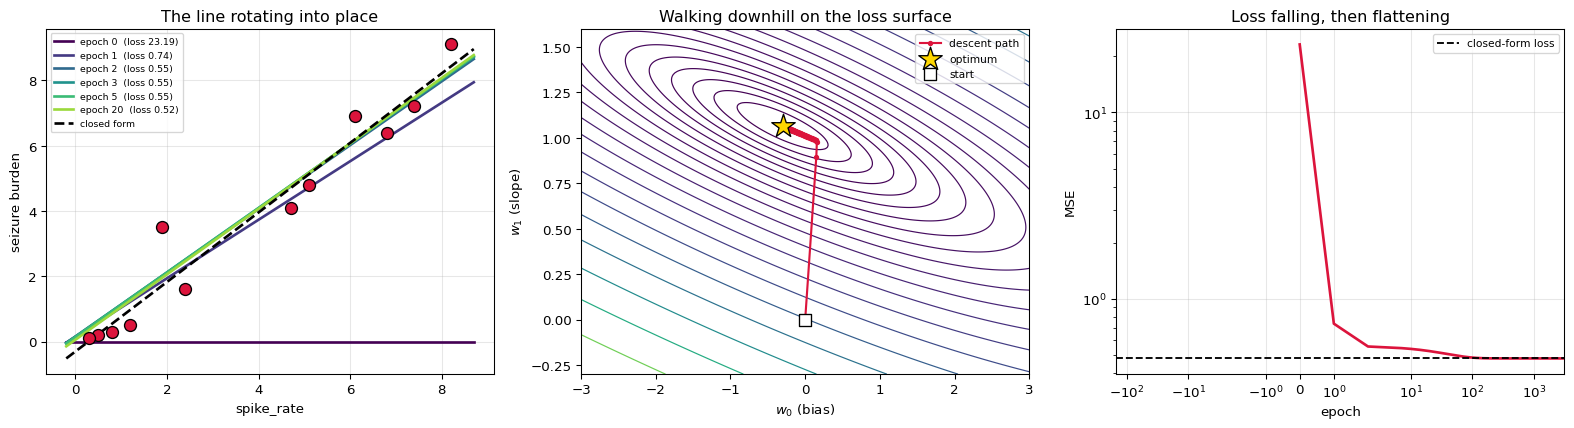

Middle panel: the path runs perpendicular to the contour lines - that IS
the gradient, which always points along the steepest direction. The steps
shorten near the optimum because the gradient itself is shrinking.


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

ax = axes[0]
gx_ = np.linspace(xs_gd.min()-.5, xs_gd.max()+.5, 100)
shades = plt.cm.viridis(np.linspace(0, .85, 6))
for k, ep in enumerate([0, 1, 2, 3, 5, 20]):
    ww = full_path[ep]
    ax.plot(gx_, ww[0] + ww[1]*gx_, color=shades[k], lw=2,
            label=f"epoch {ep}  (loss {full_loss[ep]:.2f})")
ax.plot(gx_, w_star[0] + w_star[1]*gx_, "k--", lw=2, label="closed form")
ax.scatter(xs_gd, y, s=80, c="crimson", edgecolor="k", zorder=5)
ax.set(xlabel=feature_names[1], ylabel="seizure burden",
       title="The line rotating into place")
ax.legend(fontsize=7); ax.grid(alpha=.3)

ax = axes[1]
w0g, w1g = np.meshgrid(np.linspace(-3, 3, 220), np.linspace(-0.3, 1.6, 220))
Lg = np.array([[np.mean((y - (a + b*xs_gd))**2) for a, b in zip(r0, r1)]
               for r0, r1 in zip(w0g, w1g)])
cs = ax.contour(w0g, w1g, Lg, levels=np.logspace(np.log10(Lg.min()+1e-9),
                                                 np.log10(Lg.max()), 22),
                cmap="viridis", linewidths=.9)
ax.plot(full_path[:200, 0], full_path[:200, 1], "-o", color="crimson",
        lw=1.6, ms=3, label="descent path")
ax.scatter([w_star[0]], [w_star[1]], marker="*", s=340, c="gold",
           edgecolor="k", zorder=6, label="optimum")
ax.scatter([0], [0], marker="s", s=90, c="white", edgecolor="k", zorder=6,
           label="start")
ax.set(xlabel="$w_0$ (bias)", ylabel="$w_1$ (slope)",
       title="Walking downhill on the loss surface")
ax.legend(fontsize=8)

ax = axes[2]
ax.plot(full_loss, lw=2, color="crimson")
ax.axhline(mse(w_star), ls="--", color="k", lw=1.4, label="closed-form loss")
ax.set(xlabel="epoch", ylabel="MSE", xscale="symlog", yscale="log",
       title="Loss falling, then flattening")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Middle panel: the path runs perpendicular to the contour lines - that IS")
print("the gradient, which always points along the steepest direction. The steps")
print("shorten near the optimum because the gradient itself is shrinking.")

### What the learning rate does

$\eta$ scales every step. The three failure modes are all visible on the same surface:

* **too small** &mdash; correct direction, but it crawls,
* **about right** &mdash; steady approach,
* **too large** &mdash; each step overshoots to a point further up the far wall, and the loss
  *increases*.

For squared error the boundary is knowable: descent is stable while
$\eta < 2/\lambda_{\max}$, with $\lambda_{\max}$ the largest eigenvalue of the Hessian
$\frac{2}{n}X^\top X$.

Hessian eigenvalues : [ 0.685  45.5384]
largest             : 45.538368
stable while eta    < 2 / 45.538368 = 0.04391901

         eta    vs limit      loss @10      loss @100     loss @1000       outcome
----------------------------------------------------------------------------------
      0.0005       0.01x       14.8346         0.7781         0.5182   still going
      0.0050       0.11x        0.6810         0.5181         0.4785     converged
      0.0200       0.46x        0.5382         0.4834         0.4784     converged
      0.0430       0.98x       10.1465         0.4830         0.4784     converged
      0.0480       1.09x      684.8322            inf            inf      DIVERGED
----------------------------------------------------------------------------------


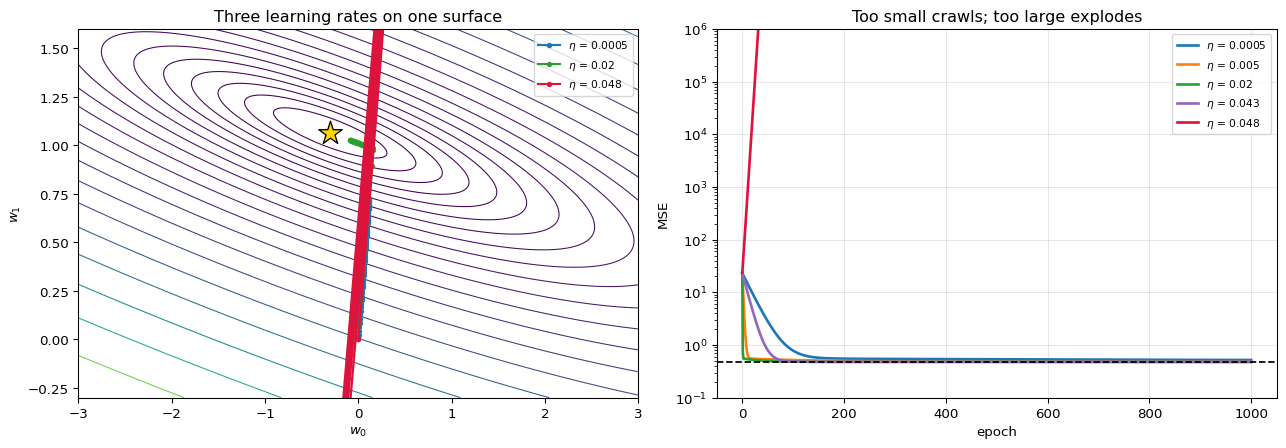


The crimson run uses eta = 0.048, just above the limit of 0.04392,
and its loss grows without bound. Nothing is wrong with the gradient -
the direction is right every single step. The step length is the problem.


In [14]:
H = 2 * A1.T @ A1 / n_samples
lam_max = np.linalg.eigvalsh(H).max()
eta_crit = 2 / lam_max
print(f"Hessian eigenvalues : {np.round(np.linalg.eigvalsh(H), 6)}")
print(f"largest             : {lam_max:.6f}")
print(f"stable while eta    < 2 / {lam_max:.6f} = {eta_crit:.8f}\n")

print(f"{'eta':>12}  {'vs limit':>10}  {'loss @10':>12}  {'loss @100':>13}  "
      f"{'loss @1000':>13}  {'outcome':>12}")
print("-" * 82)
paths = {}
for eta in (0.0005, 0.005, 0.02, 0.043, 0.048):
    ww = np.array([0.0, 0.0]); pth = [ww.copy()]; ls = [mse(ww)]
    for _ in range(1000):
        gg, _ = grads(ww)
        ww = ww - eta * gg
        if not np.all(np.isfinite(ww)) or mse(ww) > 1e12:
            pth.append(ww.copy()); ls.append(np.inf); break
        pth.append(ww.copy()); ls.append(mse(ww))
    paths[eta] = (np.array(pth), ls)
    def at(k):
        return ls[k] if k < len(ls) else ls[-1]
    out = "DIVERGED" if (not np.isfinite(ls[-1]) or ls[-1] > ls[0]) else \
          ("converged" if abs(ls[-1] - mse(w_star)) < 1e-3 else "still going")
    rel = f"{eta/eta_crit:.2f}x"
    print(f"{eta:>12.4f}  {rel:>10}  {at(10):>12.4f}  {at(100):>13.4f}  "
          f"{at(1000):>13.4g}  {out:>12}")
print("-" * 82)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
ax = axes[0]
ax.contour(w0g, w1g, Lg, levels=np.logspace(np.log10(Lg.min()+1e-9),
                                            np.log10(Lg.max()), 22),
           cmap="viridis", linewidths=.8)
for eta, col in [(0.0005, "tab:blue"), (0.02, "tab:green"), (0.048, "crimson")]:
    pth = paths[eta][0][:60]
    pth = pth[np.all(np.abs(pth) < 5, axis=1)]
    ax.plot(pth[:, 0], pth[:, 1], "-o", lw=1.6, ms=3, color=col,
            label=f"$\\eta$ = {eta}")
ax.scatter([w_star[0]], [w_star[1]], marker="*", s=340, c="gold",
           edgecolor="k", zorder=6)
ax.set(xlabel="$w_0$", ylabel="$w_1$", xlim=(-3, 3), ylim=(-0.3, 1.6),
       title="Three learning rates on one surface")
ax.legend(fontsize=8)

ax = axes[1]
for eta, col in [(0.0005, "tab:blue"), (0.005, "tab:orange"), (0.02, "tab:green"),
                 (0.043, "tab:purple"), (0.048, "crimson")]:
    ls = np.array(paths[eta][1], dtype=float)
    ls = np.where(np.isfinite(ls), ls, np.nan)
    ax.plot(ls, lw=2, color=col, label=f"$\\eta$ = {eta}")
ax.axhline(mse(w_star), ls="--", color="k", lw=1.3)
ax.set(xlabel="epoch", ylabel="MSE", yscale="log", ylim=(1e-1, 1e6),
       title="Too small crawls; too large explodes")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"\nThe crimson run uses eta = 0.048, just above the limit of "
      f"{eta_crit:.5f},")
print(f"and its loss grows without bound. Nothing is wrong with the gradient -")
print(f"the direction is right every single step. The step length is the problem.")

### Batch, stochastic, and mini-batch

Every update above used **all 12 recordings**. Two cheaper variants trade accuracy per
step for far more steps:

| Variant | Rows per update | Character |
|---|---|---|
| Batch | all $n$ | smooth, exact direction, expensive |
| Stochastic (SGD) | 1 | very noisy, very cheap |
| Mini-batch | 8&ndash;512 | the practical compromise |

The noise is not purely a cost. On a non-convex surface it can shake the parameters out
of a poor basin &mdash; which is why essentially all deep learning uses mini-batches.

       variant   rows/update    updates    final loss                     final w
----------------------------------------------------------------------------------
         batch            12         60      0.493467           [-0.0954  1.0285]
mini-batch (4)             4        180      0.513319           [-0.2844  1.0217]
    stochastic             1        720      0.752538           [-0.2737  0.9483]
----------------------------------------------------------------------------------
         exact             -          -      0.478401           [-0.3021  1.0644]


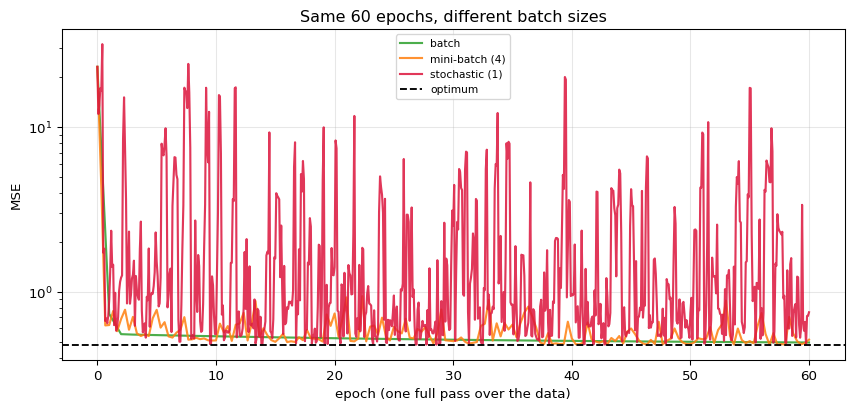

SGD makes 12 updates per epoch instead of 1, so it drops fastest at the
start - but it never settles, because each step follows a single recording
rather than the average. That permanent jitter is why real training
schedules decay the learning rate over time.


In [15]:
def run_variant(batch_size, eta=0.02, epochs=60, seed=0):
    r = np.random.default_rng(seed)
    ww = np.array([0.0, 0.0]); trace = [mse(ww)]
    for _ in range(epochs):
        idx = r.permutation(n_samples)
        for s in range(0, n_samples, batch_size):
            b = idx[s:s+batch_size]
            e_ = predict(ww, xs_gd[b]) - y[b]
            gg = np.array([2*e_.mean(), 2*np.mean(e_*xs_gd[b])])
            ww = ww - eta * gg
            trace.append(mse(ww))
    return ww, np.array(trace)

print(f"{'variant':>14}  {'rows/update':>12}  {'updates':>9}  {'final loss':>12}  "
      f"{'final w':>26}")
print("-" * 82)
for name, bs in [("batch", n_samples), ("mini-batch (4)", 4), ("stochastic", 1)]:
    ww, tr = run_variant(bs)
    print(f"{name:>14}  {bs:>12}  {len(tr)-1:>9}  {tr[-1]:>12.6f}  "
          f"{str(np.round(ww, 4)):>26}")
print("-" * 82)
print(f"{'exact':>14}  {'-':>12}  {'-':>9}  {mse(w_star):>12.6f}  "
      f"{str(np.round(w_star, 4)):>26}")

fig, ax = plt.subplots(figsize=(9, 4.4))
for name, bs, col in [("batch", n_samples, "tab:green"),
                      ("mini-batch (4)", 4, "tab:orange"),
                      ("stochastic (1)", 1, "crimson")]:
    _, tr = run_variant(bs)
    ax.plot(np.linspace(0, 60, len(tr)), tr, lw=1.6, color=col, alpha=.85, label=name)
ax.axhline(mse(w_star), ls="--", color="k", lw=1.4, label="optimum")
ax.set(xlabel="epoch (one full pass over the data)", ylabel="MSE", yscale="log",
       title="Same 60 epochs, different batch sizes")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("SGD makes 12 updates per epoch instead of 1, so it drops fastest at the")
print("start - but it never settles, because each step follows a single recording")
print("rather than the average. That permanent jitter is why real training")
print("schedules decay the learning rate over time.")

---
# 6. Scaling, and the Multi-Feature Case

The step-by-step trace used one feature. With all three, one practical detail dominates:
**feature scaling**. `age` and `spike_rate` differ by an order of magnitude, which
stretches the loss surface into a long narrow valley and makes gradient descent zig-zag
across it instead of down it.

$$\nabla \mathcal{L} = -2X^\top(\mathbf{y} - X\mathbf{w}),
\qquad
\mathbf{w} \leftarrow \mathbf{w} - \eta \, \nabla\mathcal{L}$$

In [16]:
mu, sigma = X.mean(axis=0), X.std(axis=0)
Xs = np.column_stack([np.ones(n_samples), (X - mu) / sigma])

def gd(Xm, yv, eta, iters=2000):
    wv = np.zeros(Xm.shape[1])
    hist = []
    for k in range(iters):
        grad = -2 * Xm.T @ (yv - Xm @ wv) / len(yv)
        wv = wv - eta * grad
        hist.append(((yv - Xm @ wv) ** 2).sum())
    return wv, np.array(hist)

w_gd_s, hist_s = gd(Xs, y, eta=0.05)
w_gd_r, hist_r = gd(Xd, y, eta=1e-5)

w_closed_s = np.linalg.lstsq(Xs, y, rcond=None)[0]

print("gradient descent on STANDARDISED features (eta = 0.05, 2000 steps)\n")
print(f"{'term':>14}  {'grad. descent':>14}  {'closed form':>13}  {'diff':>10}")
print("-" * 58)
for c, a, b in zip(col_names, w_gd_s, w_closed_s):
    print(f"{c:>14}  {a:>14.6f}  {b:>13.6f}  {abs(a-b):>10.2e}")
print("-" * 58)
print(f"\nMATCH with the closed form: {np.allclose(w_gd_s, w_closed_s, atol=1e-6)}")
print(f"final SS_res: gradient descent {hist_s[-1]:.6f}  vs  closed form "
      f"{((y - Xs @ w_closed_s)**2).sum():.6f}")

print(f"\n\nsame thing on RAW features - it needs eta = 1e-5 to stay stable,")
print(f"and after the same 2000 steps it has still not converged:")
print(f"   SS_res raw-feature GD  : {hist_r[-1]:.4f}")
print(f"   SS_res optimum         : {ss_res:.4f}")
print(f"   still {hist_r[-1]/ss_res:.1f}x worse than optimal")

gradient descent on STANDARDISED features (eta = 0.05, 2000 steps)

          term   grad. descent    closed form        diff
----------------------------------------------------------
      1 (bias)        3.725000       3.725000    1.78e-15
   line_length        0.534488       0.534488    8.20e-09
    spike_rate        2.343354       2.343354    2.11e-08
           age        0.191786       0.191786    2.89e-08
----------------------------------------------------------

MATCH with the closed form: True
final SS_res: gradient descent 4.453102  vs  closed form 4.453102


same thing on RAW features - it needs eta = 1e-5 to stay stable,
and after the same 2000 steps it has still not converged:
   SS_res raw-feature GD  : 28.5471
   SS_res optimum         : 4.4531
   still 6.4x worse than optimal


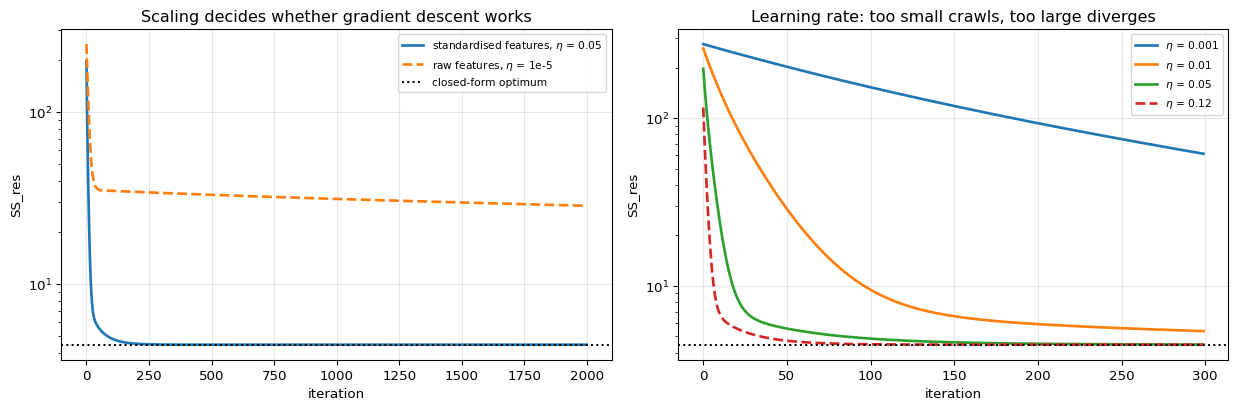

The dashed curve on the right is past the stability limit and climbs away.
For least squares that limit is knowable: eta < 2 / largest eigenvalue of
(2/n) X^T X.
   largest eigenvalue = 5.5205  ->  stable for eta < 0.3623


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(hist_s, lw=2, label="standardised features, $\\eta$ = 0.05")
axes[0].plot(hist_r, lw=2, ls="--", label="raw features, $\\eta$ = 1e-5")
axes[0].axhline(ss_res, color="k", ls=":", lw=1.5, label="closed-form optimum")
axes[0].set(xlabel="iteration", ylabel="SS_res", yscale="log",
            title="Scaling decides whether gradient descent works")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

for eta, style in [(0.001, "-"), (0.01, "-"), (0.05, "-"), (0.12, "--")]:
    _, hh = gd(Xs, y, eta=eta, iters=300)
    axes[1].plot(hh, style, lw=2, label=f"$\\eta$ = {eta}")
axes[1].axhline(ss_res, color="k", ls=":", lw=1.5)
axes[1].set(xlabel="iteration", ylabel="SS_res", yscale="log",
            title="Learning rate: too small crawls, too large diverges")
axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("The dashed curve on the right is past the stability limit and climbs away.")
print("For least squares that limit is knowable: eta < 2 / largest eigenvalue of")
print("(2/n) X^T X.")
lam_max = np.linalg.eigvalsh(2 * Xs.T @ Xs / n_samples).max()
print(f"   largest eigenvalue = {lam_max:.4f}  ->  stable for eta < {2/lam_max:.4f}")

---
# 7. Ridge and Lasso

When features are correlated, $X^\top X$ is near-singular, its inverse blows up, and the
fitted weights become large and unstable. Both remedies add a penalty on the size of
$\mathbf{w}$:

$$\text{Ridge (L2):}\quad \lVert \mathbf{y} - X\mathbf{w}\rVert^2 + \alpha\lVert\mathbf{w}\rVert_2^2
\qquad\Longrightarrow\qquad
\mathbf{w} = (X^\top X + \alpha I)^{-1}X^\top\mathbf{y}$$

$$\text{Lasso (L1):}\quad \lVert \mathbf{y} - X\mathbf{w}\rVert^2 + \alpha\lVert\mathbf{w}\rVert_1
\qquad\Longrightarrow\qquad \text{no closed form}$$

Ridge stays solvable in closed form &mdash; adding $\alpha I$ to the diagonal makes the matrix
invertible again. Lasso does not, because $|w|$ is not differentiable at zero. That kink
is precisely what drives coefficients to **exactly** zero, making lasso a feature
selector while ridge only shrinks.

In [18]:
from sklearn.linear_model import Ridge, Lasso

Xc = (X - mu) / sigma          # penalties are only meaningful on comparable scales
alphas = [0.0, 0.1, 1.0, 10.0, 100.0]

print("ridge, computed by hand from (X^T X + alpha I)^-1 X^T y")
print("(the bias column is left unpenalised, as sklearn does)\n")
print(f"{'alpha':>8}  " + "  ".join(f"{f:>12}" for f in feature_names) +
      f"  {'||w||':>9}  {'R^2':>8}")
print("-" * 74)
ridge_paths = []
for a in alphas:
    Pen = a * np.eye(n_features)
    wr = np.linalg.solve(Xc.T @ Xc + Pen, Xc.T @ (y - y.mean()))
    pred = Xc @ wr + y.mean()
    r2a = 1 - ((y - pred) ** 2).sum() / ss_tot
    ridge_paths.append(wr)
    print(f"{a:>8.1f}  " + "  ".join(f"{v:>12.5f}" for v in wr) +
          f"  {np.linalg.norm(wr):>9.4f}  {r2a:>8.5f}")
print("-" * 74)

sk_r = Ridge(alpha=1.0, fit_intercept=True).fit(Xc, y)
mine = np.linalg.solve(Xc.T @ Xc + 1.0 * np.eye(n_features), Xc.T @ (y - y.mean()))
print(f"\nour ridge (alpha=1) : {np.round(mine, 8)}")
print(f"sklearn Ridge       : {np.round(sk_r.coef_, 8)}")
print(f"MATCH: {np.allclose(mine, sk_r.coef_, atol=1e-8)}")

ridge, computed by hand from (X^T X + alpha I)^-1 X^T y
(the bias column is left unpenalised, as sklearn does)

   alpha   line_length    spike_rate           age      ||w||       R^2
--------------------------------------------------------------------------
     0.0       0.53449       2.34335       0.19179     2.4112   0.96016
     0.1       0.54538       2.24472       0.26955     2.3257   0.95998
     1.0       0.63211       1.74336       0.60086     1.9493   0.95355
    10.0       0.68444       0.94379       0.72615     1.3735   0.88587
   100.0       0.24061       0.27221       0.24989     0.4409   0.40543
--------------------------------------------------------------------------

our ridge (alpha=1) : [0.6321 1.7434 0.6009]
sklearn Ridge       : [0.6321 1.7434 0.6009]
MATCH: True


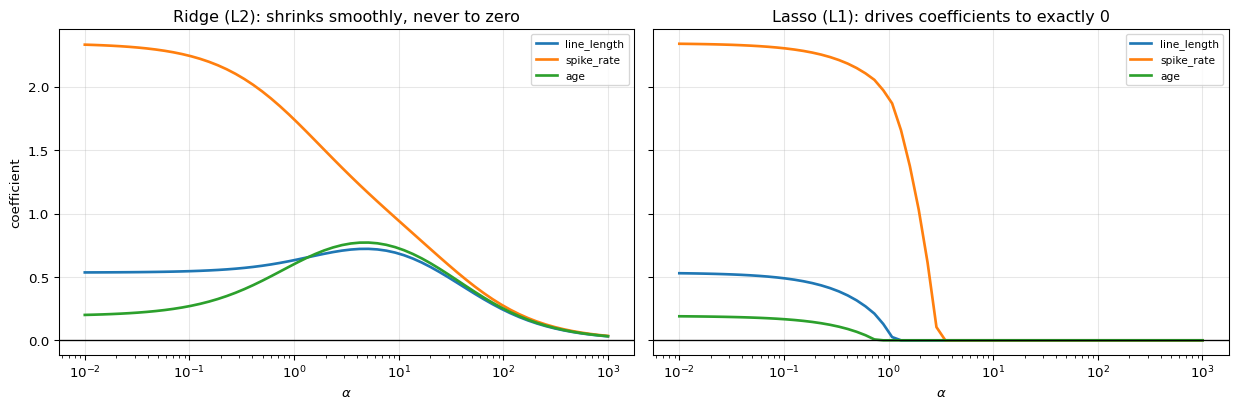

    alpha    ridge: # exactly 0    lasso: # exactly 0
------------------------------------------------------
      0.1                     0                     0
      1.0                     0                     1
      5.0                     0                     3
     20.0                     0                     3
------------------------------------------------------

Ridge never reaches zero exactly; lasso does, and that is the whole
difference in one table.


In [19]:
grid = np.logspace(-2, 3, 60)
rp = np.array([np.linalg.solve(Xc.T @ Xc + a*np.eye(n_features), Xc.T @ (y - y.mean()))
               for a in grid])
lp = np.array([Lasso(alpha=a, max_iter=50000).fit(Xc, y).coef_ for a in grid])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for k, f in enumerate(feature_names):
    axes[0].plot(grid, rp[:, k], lw=2, label=f)
    axes[1].plot(grid, lp[:, k], lw=2, label=f)
for ax, ttl in zip(axes, ["Ridge (L2): shrinks smoothly, never to zero",
                          "Lasso (L1): drives coefficients to exactly 0"]):
    ax.set(xscale="log", xlabel=r"$\alpha$", title=ttl)
    ax.axhline(0, color="k", lw=1); ax.legend(fontsize=8); ax.grid(alpha=.3)
axes[0].set_ylabel("coefficient")
plt.tight_layout(); plt.show()

print(f"{'alpha':>9}  {'ridge: # exactly 0':>20}  {'lasso: # exactly 0':>20}")
print("-" * 54)
for a in (0.1, 1.0, 5.0, 20.0):
    wr = np.linalg.solve(Xc.T @ Xc + a*np.eye(n_features), Xc.T @ (y - y.mean()))
    wl = Lasso(alpha=a, max_iter=50000).fit(Xc, y).coef_
    print(f"{a:>9.1f}  {int((np.abs(wr) < 1e-10).sum()):>20}  "
          f"{int((np.abs(wl) < 1e-10).sum()):>20}")
print("-" * 54)
print("\nRidge never reaches zero exactly; lasso does, and that is the whole")
print("difference in one table.")

---
# 8. Checking Against scikit-learn

In [20]:
from sklearn.linear_model import LinearRegression

sk = LinearRegression().fit(X, y)

print(f"{'term':>14}  {'ours':>13}  {'sklearn':>13}  {'diff':>10}")
print("-" * 56)
print(f"{'intercept':>14}  {w[0]:>13.8f}  {sk.intercept_:>13.8f}  "
      f"{abs(w[0]-sk.intercept_):>10.2e}")
for k, f in enumerate(feature_names):
    print(f"{f:>14}  {w[k+1]:>13.8f}  {sk.coef_[k]:>13.8f}  "
          f"{abs(w[k+1]-sk.coef_[k]):>10.2e}")
print("-" * 56)
print(f"\ncoefficients MATCH : {np.allclose(w[1:], sk.coef_) and np.isclose(w[0], sk.intercept_)}")
print(f"predictions MATCH  : {np.allclose(y_hat, sk.predict(X))}")
print(f"R^2 ours {r2:.8f}  sklearn {sk.score(X, y):.8f}  "
      f"MATCH: {np.isclose(r2, sk.score(X, y))}")

lstsq_w = np.linalg.lstsq(Xd, y, rcond=None)[0]
print(f"\nvs np.linalg.lstsq (QR-based, more stable than inverting): "
      f"{np.allclose(w, lstsq_w)}")
print("\nIn production never form (X^T X)^-1 explicitly - solve the system instead.")
print("The inverse was written out here only because the point was to show it.")

          term           ours        sklearn        diff
--------------------------------------------------------
     intercept    -1.14974437    -1.14974437    3.55e-15
   line_length     0.03432127     0.03432127    6.94e-18
    spike_rate     0.83915992     0.83915992    1.03e-14
           age     0.01331754     0.01331754    2.66e-15
--------------------------------------------------------

coefficients MATCH : True
predictions MATCH  : True
R^2 ours 0.96015567  sklearn 0.96015567  MATCH: True

vs np.linalg.lstsq (QR-based, more stable than inverting): True

In production never form (X^T X)^-1 explicitly - solve the system instead.
The inverse was written out here only because the point was to show it.


---
# 9. Summary

| Stage | Formula | Value here |
|---|---|---|
| Model | $\hat{\mathbf{y}} = X\mathbf{w}$ | 4 weights (bias + 3) |
| Loss | $\lVert\mathbf{y} - X\mathbf{w}\rVert^2$ | convex quadratic |
| Solution | $\mathbf{w}^{*} = (X^\top X)^{-1}X^\top\mathbf{y}$ | closed form, one step |
| Optimality | $X^\top(\mathbf{y} - X\mathbf{w}) = \mathbf{0}$ | verified to $10^{-9}$ |
| Fit | $R^2 = 1 - SS_{res}/SS_{tot}$ | see output above |
| Ridge | $(X^\top X + \alpha I)^{-1}X^\top\mathbf{y}$ | shrinks, never zeroes |
| Lasso | L1 penalty, iterative | zeroes coefficients |

**The one idea:** least squares is a **projection**. $X\mathbf{w}$ can only reach the
column space of $X$, so the best it can do is the closest point in that subspace to
$\mathbf{y}$ &mdash; which is why the residual comes out perpendicular to every feature.

**What is deliberately left out:** standard errors, $t$- and $p$-values, confidence
intervals, the Gauss-Markov assumptions and what breaks when they fail,
heteroscedasticity, weighted least squares, polynomial and spline bases, and elastic net.

**What comes next:** logistic regression keeps this exact linear form, $\mathbf{x}^\top\mathbf{w}$,
and only changes what happens to it afterwards &mdash; a sigmoid instead of the identity,
log-loss instead of squared error. That single change destroys the closed form and forces
the iterative approach shown in section 5.